# Supplemental Figure 3, Panel C

Comparison of log2FC accessibility BAFinh vs Veh (6h, 10uM) at active enhancers residing within annotated superenhancers vs outside of superenhancers

*Output: PanelC.pdf*

In [24]:
# Setup

[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/SuppFig3/archive/PanelC"

In [12]:
# load packages
library(tidyverse)
library(rtracklayer)
library(here)
here::i_am("figures/SuppFig3/PanelC/PanelC.ipynb")
sessionInfo()

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats4    stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2           rtracklayer_1.58.0   GenomicRanges_1.50.2
 [4] GenomeInfoDb_1.34.9  IRanges_2.32.0       S4Vectors_0.36.2    
 [7] BiocGenerics_0.44.0  ggrastr_1.0.2        patchwork_1.3.0     
[10] lubridate_1.9.4      forcats_1.0.0        stringr_1.5.1       
[13] dpl

# Load data

In [27]:
#load active enhancer coordinates and BAFinh vs Vehicle ATAC-seq log2FCs
atac <- read.delim(
  here("inputs", "DARs", "time_6h_DARs.tsv"),
  sep = "\t"
) %>%
  filter(type == "active_enh")

#convert to GR
atac_gr <- GRanges(seqnames=atac$seqnames, ranges=IRanges(start=atac$start, end=atac$end, logFC=atac$logFC))
#load super-enhancer coordinates from SEdb and dbSUPER databases
# load super-enhancer coordinates from SEdb and dbSUPER databases
SEdb <- import(
  here("figures", "SuppFig3", "PanelC", "SEdb_3.0", "SE_01_0030_SE_hg38_noHeader_bed3.bed")
)

dbSUPER <- import(
  here("figures", "SuppFig3", "PanelC", "dbSUPER", "hg38_GM12878.bed")
)

str(SEdb)
str(dbSUPER)

Formal class 'GRanges' [package "GenomicRanges"] with 7 slots
  ..@ seqnames       :Formal class 'Rle' [package "S4Vectors"] with 4 slots
  .. .. ..@ values         : Factor w/ 23 levels "chr1","chr10",..: 1 2 3 4 5 6 7 8 9 10 ...
  .. .. ..@ lengths        : int [1:23] 20 10 5 8 3 9 7 2 9 3 ...
  .. .. ..@ elementMetadata: NULL
  .. .. ..@ metadata       : list()
  ..@ ranges         :Formal class 'IRanges' [package "IRanges"] with 6 slots
  .. .. ..@ start          : int [1:153] 101356835 111191714 111591890 116537858 12038975 150560298 160605070 160703575 167616435 203272987 ...
  .. .. ..@ width          : int [1:153] 55375 35402 38357 34360 50203 20421 81320 87621 65598 55898 ...
  .. .. ..@ NAMES          : NULL
  .. .. ..@ elementType    : chr "ANY"
  .. .. ..@ elementMetadata: NULL
  .. .. ..@ metadata       : list()
  ..@ strand         :Formal class 'Rle' [package "S4Vectors"] with 4 slots
  .. .. ..@ values         : Factor w/ 3 levels "+","-","*": 3
  .. .. ..@ lengths     

# Annotate active enhancers

In [29]:
#annotate active enhancers based on overlap with SEdb and dbSUPER super-enhancers
atac$in_SEdb=FALSE
atac$in_SEdb <- countOverlaps(atac_gr,SEdb)>0

atac$in_dbSUPER=FALSE
atac$in_dbSUPER <- countOverlaps(atac_gr,dbSUPER)>0

# Generate plot

SE,n()
<lgl>,<int>
FALSE,17562
TRUE,1783


[1] 3.119627e-124

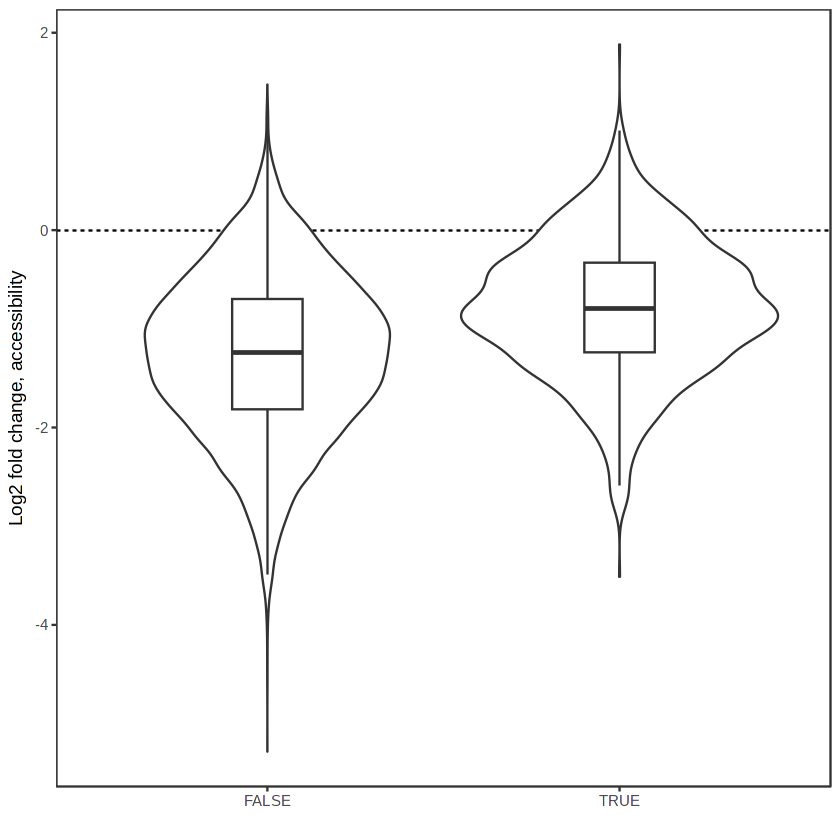

In [30]:
#plot log2FCs of active enhancers in SEs vs outside of SEs
atac %>% 
    ggplot(aes(x=in_SEdb|in_dbSUPER, y=logFC)) + 
    theme_bw() + theme(panel.grid=element_blank()) + 
    geom_hline(yintercept=0, linetype=2) + 
    geom_violin() + geom_boxplot(width=.2, outlier.shape=NA) +
    xlab("") + ylab("Log2 fold change, accessibility")
ggsave(here("figures", "SuppFig3","PanelC", "PanelC.pdf"), width=2, height=3)

#count # of active enhancers residing inside and outside of SEs
atac %>% group_by(SE=in_SEdb|in_dbSUPER) %>% summarize(n())
#stats on difference in log2FCs between SE+ and SE- active enhancers
wilcox.test(atac[which(atac$in_SEdb|atac$in_dbSUPER),]$logFC, atac[-which(atac$in_SEdb|atac$in_dbSUPER),]$logFC)$p.value

In [28]:
here()

[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"